# LAB 3 - EEG

Giacomo Roggero - groggero@student.ethz.ch - 25-945-981,  

Lakshmigan Sivakolunthu - lsivakolu@student.ethz.ch - 20-927-976,  

Carl Linus Ehlert - ehlertl@student.ethz.ch - 25-934-415

## Imports & Function definitions:

In [27]:
# %pip install plotly mne nbformat
# Imports
import pickle
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, freqz
import plotly.graph_objs as go
import plotly.io as pio
import plotly.express as px
from plotly.subplots import make_subplots
from sklearn.model_selection import train_test_split
from mne.viz import plot_topomap
import mne.decoding
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
import pandas as pd


In [28]:
# ---------- Loading ----------
def load_data(path='data.pkl', verbose=True):
    """Load the lab pickle file (a dict) and optionally print the shape of every entry."""
    with open(path, 'rb') as f:
        data = pickle.load(f)
    if verbose:
        for key, value in data.items():
            print(f'{key:20s} shape={np.shape(value)}')
    return data


def get_trial(data, trial):
    """Return the EEG and IMU arrays of one trial (1 or 2) under short, uniform names."""
    return {
        'eeg':      data[f'eeg_data{trial}'],        # (n_samples, 8)
        'eeg_time': data[f'eeg_timestamps{trial}'],  # (n_samples,)  500 Hz
        'imu':      data[f'imu_acc{trial}'],         # (n_samples, 3) irregular sampling
        'imu_time': data[f'imu_time{trial}'],        # (n_samples,)
    }


# ---------- Plotting ----------
EVENT_COLORS = ['red', 'purple', 'black', 'saddlebrown', 'magenta', 'teal']


def plot_signals(time, signals, title='', ylabel='', channel_names=None, separate=False,
                 events=None, event_labels=None, interactive=False, xlim=None, show=True):
    """
    Plot a (multichannel) signal against time. Works for raw EEG, filtered EEG, IMU, ...

    time          : (n_samples,) time axis in seconds
    signals       : (n_samples, n_channels) or (n_samples,) array
    channel_names : names for legend / subplot labels (default 'Ch 1', 'Ch 2', ...)
    separate      : True  -> one subplot per channel with a shared time axis (good for EEG)
                    False -> all channels on one axis (good for IMU x/y/z)
    events        : optional event times in seconds, drawn as dashed vertical lines
    event_labels  : optional label per event (e.g. 'writing', 'eating');
                    events with the same label share a colour
    interactive   : True  -> plotly (zoom + cursor read-out, use this for labelling)
                    False -> matplotlib (static, use this for the report)
    xlim          : optional (t_start, t_end) to zoom in
    show          : display the figure; the figure is returned either way
    """
    time = np.asarray(time)
    signals = np.asarray(signals)
    if signals.ndim == 1:
        signals = signals[:, None]
    if signals.shape[0] != time.shape[0]:
        raise ValueError(f'time has {time.shape[0]} samples but signals has {signals.shape[0]}')
    n_ch = signals.shape[1]
    if channel_names is None:
        channel_names = [f'Ch {i + 1}' for i in range(n_ch)]

    events = [] if events is None else list(events)
    if event_labels is None:
        event_labels = [None] * len(events)
    if len(event_labels) != len(events):
        raise ValueError('event_labels must have one entry per event')
    unique_labels = list(dict.fromkeys(event_labels))
    color_of = {lab: ('gray' if lab is None else EVENT_COLORS[i % len(EVENT_COLORS)])
                for i, lab in enumerate(unique_labels)}

    n_rows = n_ch if separate else 1

    if interactive:
        fig = make_subplots(rows=n_rows, cols=1, shared_xaxes=True, vertical_spacing=0.01)
        for i in range(n_ch):
            fig.add_trace(go.Scattergl(x=time, y=signals[:, i], mode='lines',
                                       name=channel_names[i], line=dict(width=1)),
                          row=i + 1 if separate else 1, col=1)
            if separate:
                fig.update_yaxes(title_text=channel_names[i], row=i + 1, col=1)
        for t, lab in zip(events, event_labels):
            fig.add_vline(x=t, line=dict(color=color_of[lab], dash='dash', width=1))
        for lab in unique_labels:  # legend entries for the event lines
            if lab is not None:
                fig.add_trace(go.Scatter(x=[None], y=[None], mode='lines', name=lab,
                                         line=dict(color=color_of[lab], dash='dash')))
        if not separate:
            fig.update_yaxes(title_text=ylabel)
        fig.update_xaxes(title_text='Time (s)', row=n_rows, col=1)
        if xlim is not None:
            fig.update_xaxes(range=list(xlim))
        fig.update_layout(title=title, height=180 * n_rows + 150 if separate else 450)
        if show:
            fig.show()
        return fig

    fig, axes = plt.subplots(n_rows, 1, sharex=True, squeeze=False,
                             figsize=(14, 1.5 * n_rows + 1.5 if separate else 4.5))
    axes = axes[:, 0]
    for i in range(n_ch):
        ax = axes[i] if separate else axes[0]
        ax.plot(time, signals[:, i], lw=0.6, label=channel_names[i])
        if separate:
            ax.set_ylabel(channel_names[i])
    for ax in axes:
        for t, lab in zip(events, event_labels):
            ax.axvline(t, color=color_of[lab], ls='--', lw=1)
    handles = [plt.Line2D([], [], color=color_of[lab], ls='--', label=lab)
               for lab in unique_labels if lab is not None]
    if separate:
        fig.supylabel(ylabel)
        if handles:
            axes[0].legend(handles=handles, loc='upper right')
    else:
        axes[0].set_ylabel(ylabel)
        axes[0].legend(handles=axes[0].get_lines()[:n_ch] + handles, loc='upper right')
    axes[-1].set_xlabel('Time (s)')
    if xlim is not None:
        axes[-1].set_xlim(xlim)
    fig.suptitle(title)
    fig.tight_layout()
    if show:
        plt.show()
    return fig


def plot_trial(data, trial, eeg=None, eeg_title='EEG', interactive=False, **kwargs):
    """
    Lab task 4/5: plot the EEG (one subplot per channel) and the IMU (x/y/z on one axis) of a trial.
    Pass `eeg` to plot e.g. the filtered EEG instead of the raw data.
    Extra keyword arguments (events, event_labels, xlim, ...) are forwarded to plot_signals.
    """
    d = get_trial(data, trial)
    eeg = d['eeg'] if eeg is None else eeg
    fig_eeg = plot_signals(d['eeg_time'], eeg, title=f'{eeg_title} - trial {trial}',
                           ylabel='Amplitude', separate=True, interactive=interactive, **kwargs)
    fig_imu = plot_signals(d['imu_time'], d['imu'], title=f'IMU acceleration - trial {trial}',
                           ylabel='Acceleration (g)', channel_names=['x', 'y', 'z'],
                           interactive=interactive, **kwargs)
    return fig_eeg, fig_imu

# ---------- Filtering ----------
def bandpass_filter(signals, fs, low=1.0, high=30.0, order=4):
    """
    Zero-phase Butterworth band-pass filter, applied channel by channel.

    signals : (n_samples, n_channels) or (n_samples,) array
    fs      : sampling frequency in Hz
    low/high: pass-band edges in Hz
    order   : Butterworth order. filtfilt runs the filter forward and backward,
              so there is no phase shift and the effective order is doubled.
    """
    b, a = butter(order, [low, high], btype='bandpass', fs=fs)
    signals = np.asarray(signals, dtype=float)
    if signals.ndim == 1:
        return filtfilt(b, a, signals)
    filtered = np.zeros_like(signals)
    for ch in range(signals.shape[1]):          # loop through each channel
        filtered[:, ch] = filtfilt(b, a, signals[:, ch])
    return filtered


def plot_filter_response(fs, low=1.0, high=30.0, order=4, show=True):
    """Magnitude response of the band-pass (single pass and the effective filtfilt response)."""
    b, a = butter(order, [low, high], btype='bandpass', fs=fs)
    f, h = freqz(b, a, worN=8192, fs=fs)
    mag = np.abs(h)
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(f, 20 * np.log10(np.maximum(mag, 1e-12)), label=f'butter, order {order}')
    ax.plot(f, 20 * np.log10(np.maximum(mag ** 2, 1e-12)), '--', label='filtfilt (applied twice)')
    for edge in (low, high):
        ax.axvline(edge, color='gray', ls=':')
    ax.axhline(-3, color='gray', ls=':', lw=0.8)
    ax.set_xscale('log')
    ax.set_xlim(0.1, fs / 2)
    ax.set_ylim(-80, 5)
    ax.set_xlabel('Frequency (Hz)')
    ax.set_ylabel('Gain (dB)')
    ax.set_title(f'Band-pass filter {low}-{high} Hz (fs = {fs} Hz)')
    ax.legend()
    fig.tight_layout()
    if show:
        plt.show()
    return fig

# ---------- Labelling & epoching ----------
CLASS_IDS = {'writing': 0, 'eating': 1}


def alternate_labels(n_events, order=('writing', 'eating')):
    """Class names for events that alternate, e.g. writing, eating, writing, eating, ..."""
    return [order[i % len(order)] for i in range(n_events)]


def event_durations(starts, t_end):
    """Duration of every event (end of event N = start of event N+1, last one ends at t_end)."""
    return np.diff(np.append(starts, t_end))


def label_eeg(eeg_time, starts, classes, class_ids=CLASS_IDS):
    """
    Step 6: give every EEG sample the class id of the event it belongs to.
    Samples before the first event get -1 (unlabelled).
    """
    starts = np.asarray(starts, dtype=float)
    if len(starts) != len(classes):
        raise ValueError(f'{len(starts)} event starts but {len(classes)} classes')
    ids = np.array([class_ids[c] for c in classes])
    event_idx = np.searchsorted(starts, eeg_time, side='right') - 1   # event each sample falls in
    return np.where(event_idx >= 0, ids[np.clip(event_idx, 0, None)], -1)


def discard_initial(signals, time, first_event_start):
    """Step 7: drop everything recorded before the first event (data collection starts there)."""
    keep = np.asarray(time) >= first_event_start
    return np.asarray(signals)[keep], np.asarray(time)[keep]


def extract_epochs(eeg, eeg_time, starts, classes, duration, fs=500,
                   class_ids=CLASS_IDS, verbose=True):
    """
    Steps 7 + 8: discard the data before the first event and keep only the first
    `duration` seconds of EEG after every event start.

    eeg        : (n_samples, n_channels) EEG (use the filtered data)
    eeg_time   : (n_samples,) EEG timestamps in seconds
    starts     : event start times in seconds (your manually extracted time points)
    classes    : class name of every event
    duration   : seconds of EEG to keep per event (2 s in step 8; 1 s and 4 s for Q3).
                 Always the full duration: for events shorter than this the window
                 runs into the next event.

    Returns X with shape (n_events, n_channels, n_samples_per_event) and y (n_events,) class ids.
    """
    starts = np.asarray(starts, dtype=float)
    if len(starts) != len(classes):
        raise ValueError(f'{len(starts)} event starts but {len(classes)} classes')
    eeg, eeg_time = discard_initial(eeg, eeg_time, starts[0])      # step 7

    n_keep = int(round(duration * fs))
    durations = event_durations(starts, eeg_time[-1])
    X, y, too_short = [], [], 0
    for start, cls, dur in zip(starts, classes, durations):
        i0 = np.searchsorted(eeg_time, start)          # first EEG sample at/after the event start
        if i0 + n_keep > len(eeg_time):
            if verbose:
                print(f'  skipped event at {start:.2f} s: less than {duration} s of data left')
            continue
        too_short += dur < duration
        X.append(eeg[i0:i0 + n_keep].T)                # (n_channels, n_keep)
        y.append(class_ids[cls])
    X, y = np.stack(X), np.array(y)
    if verbose:
        counts = {c: int(np.sum(y == i)) for c, i in class_ids.items()}
        print(f'  {len(y)} events x {X.shape[1]} channels x {X.shape[2]} samples ({duration} s), '
              f'per class: {counts}')
        if too_short:
            print(f'  note: {too_short} events are shorter than {duration} s, '
                  f'so their window runs into the next event')
    return X, y



## 4. Load & Plot the EEG & IMU data for both trials

eeg_data1            shape=(74963, 8)
eeg_data2            shape=(72760, 8)
eeg_timestamps1      shape=(74963,)
eeg_timestamps2      shape=(72760,)
imu_time1            shape=(10020,)
imu_time2            shape=(9723,)
imu_acc1             shape=(10020, 3)
imu_acc2             shape=(9723, 3)
chans                shape=(8, 2)
trial1_event_times   shape=(30,)
trial2_event_times   shape=(24,)
trial1_event_ids     shape=(30,)
trial2_event_ids     shape=(24,)
EEG trial 1 shape: (74963, 8)


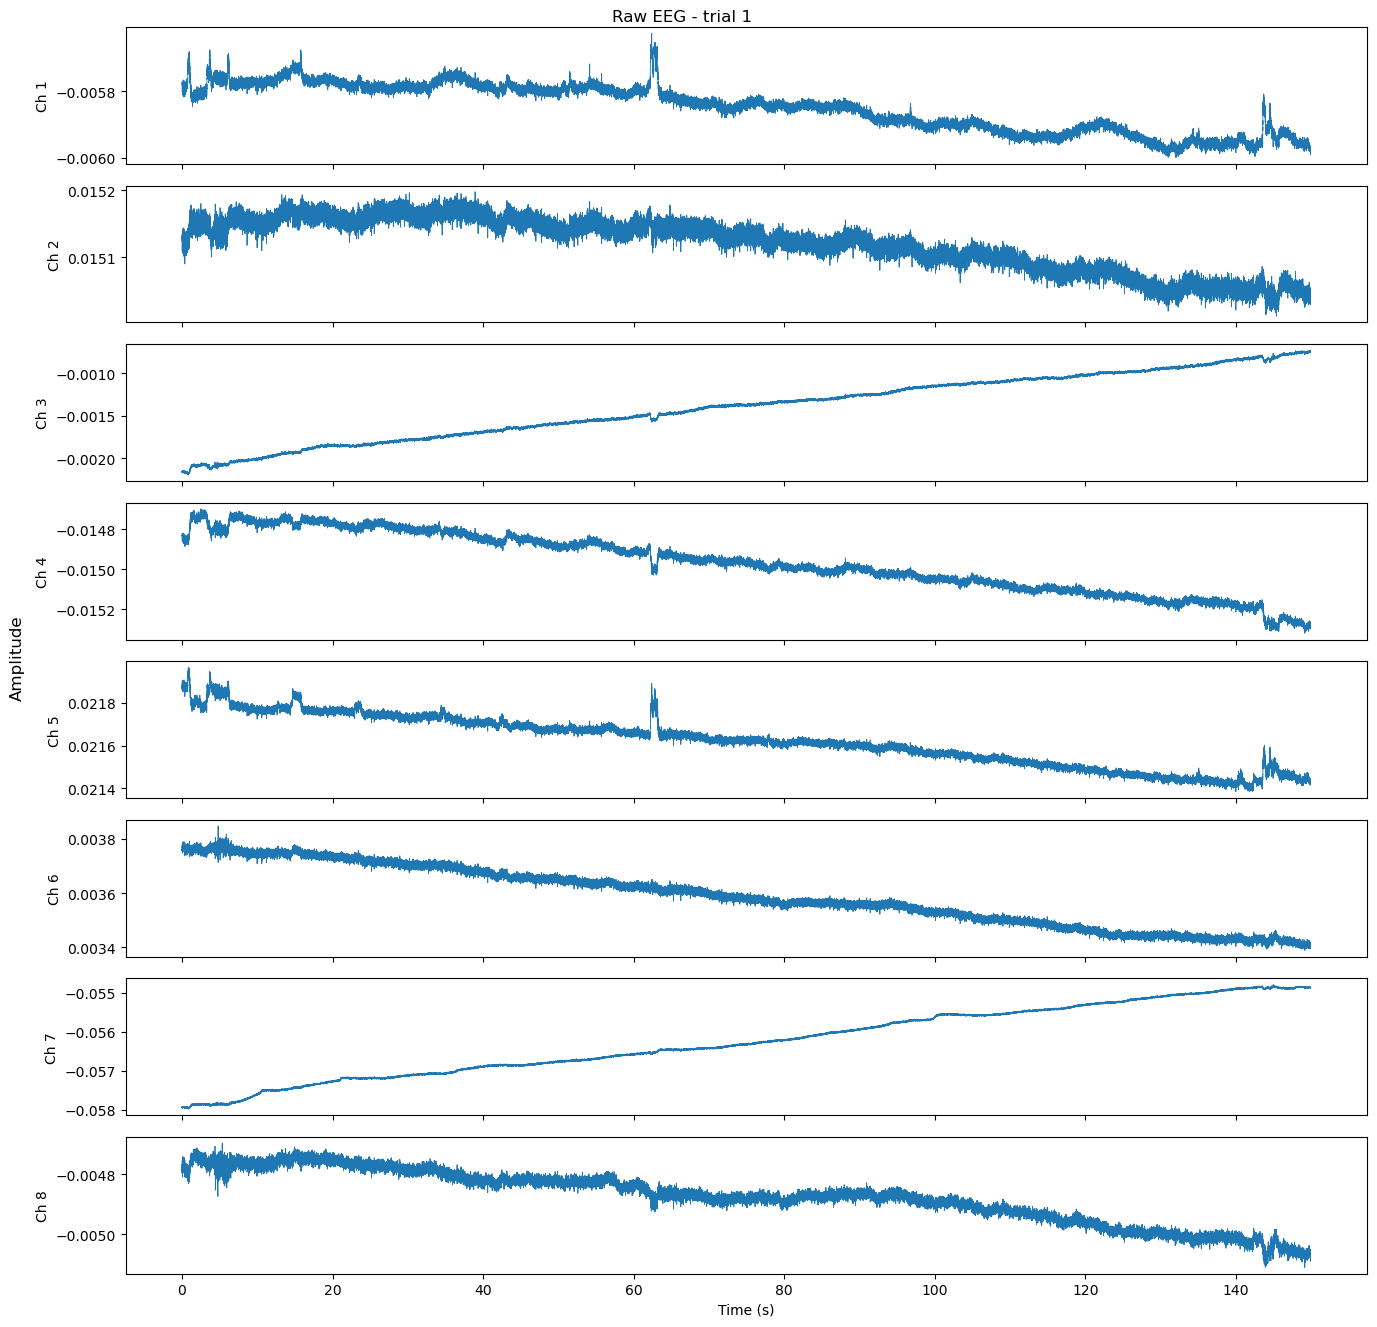

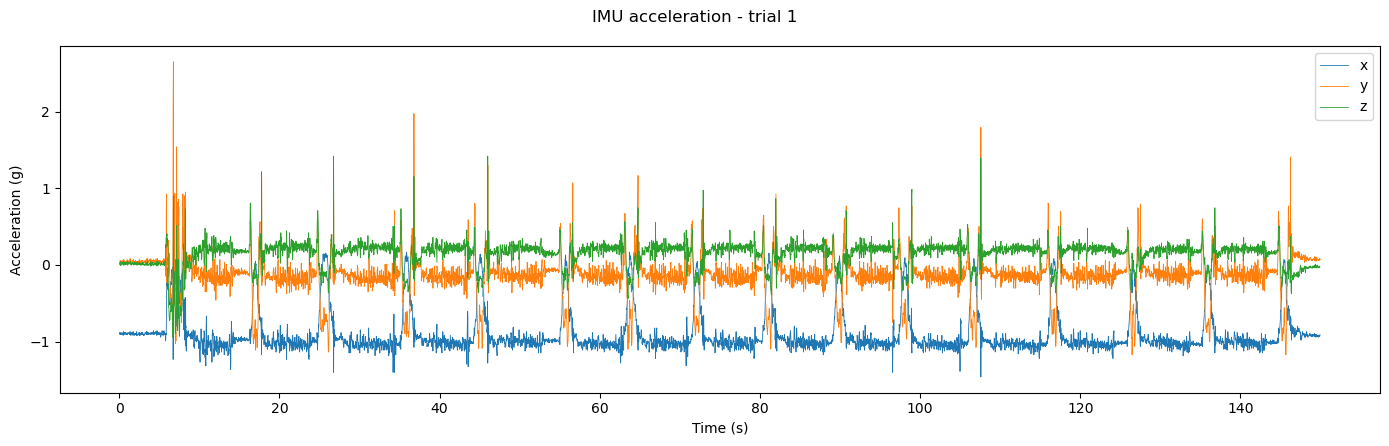

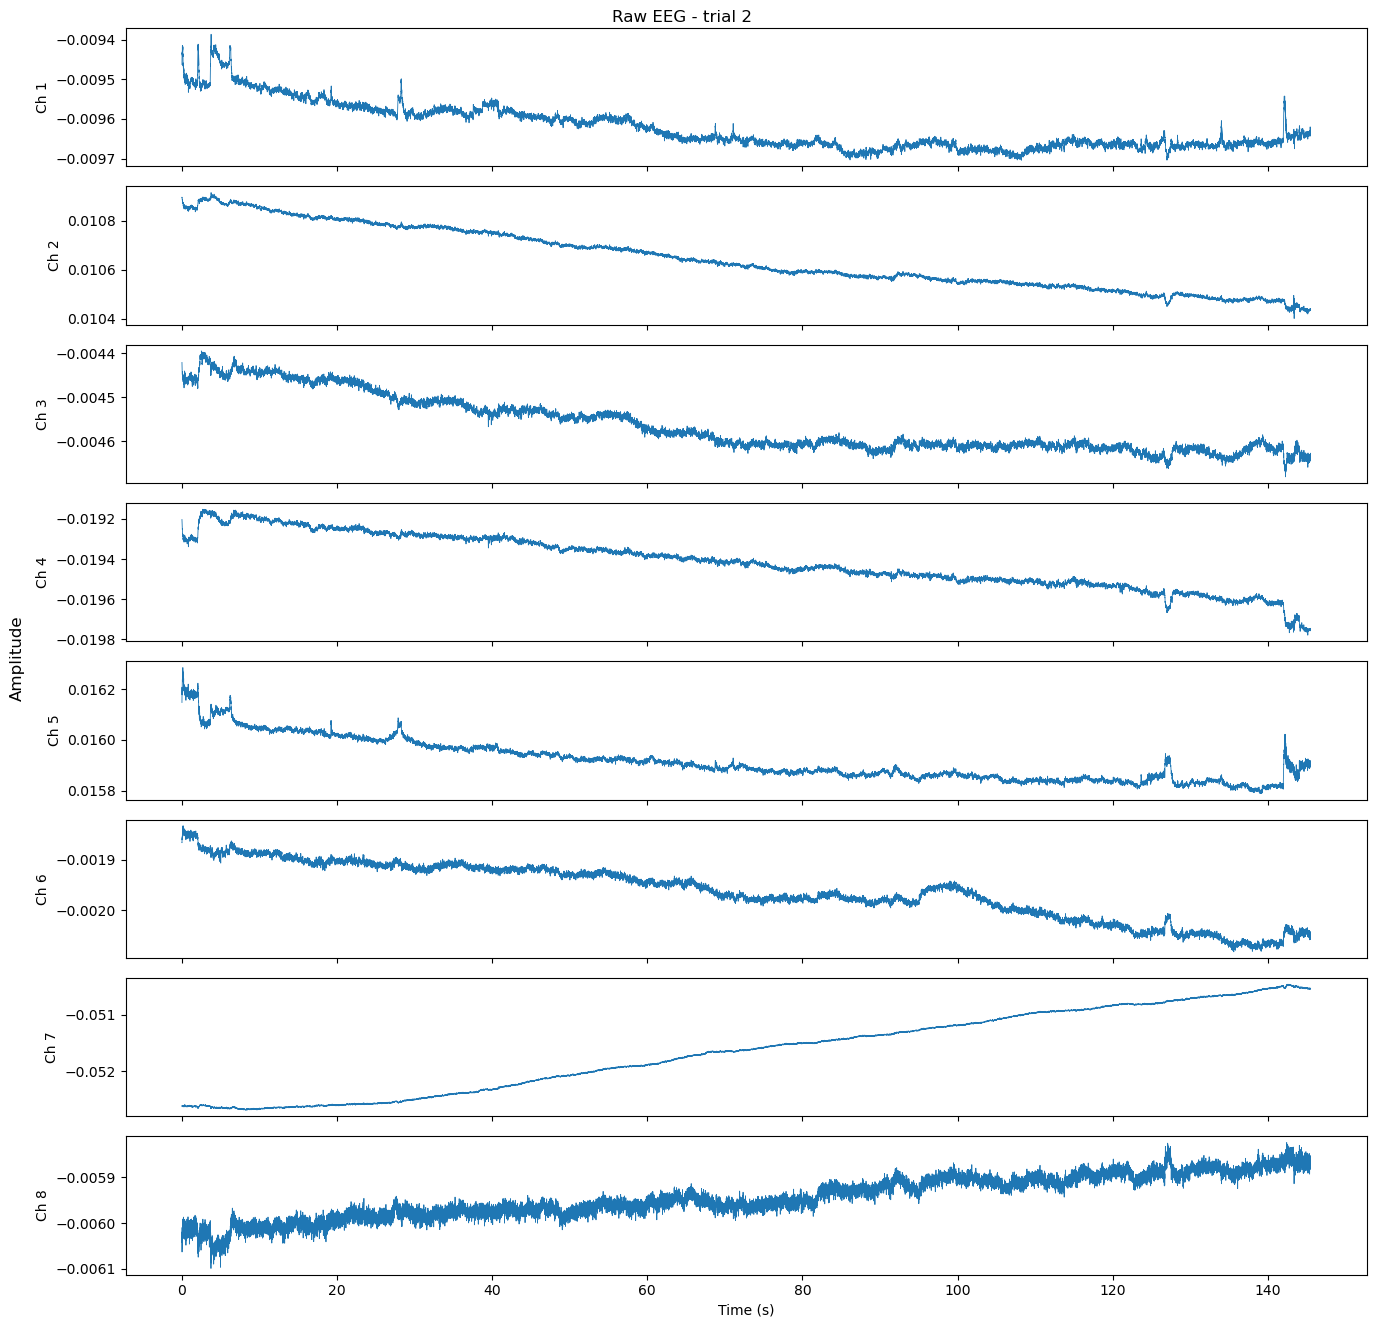

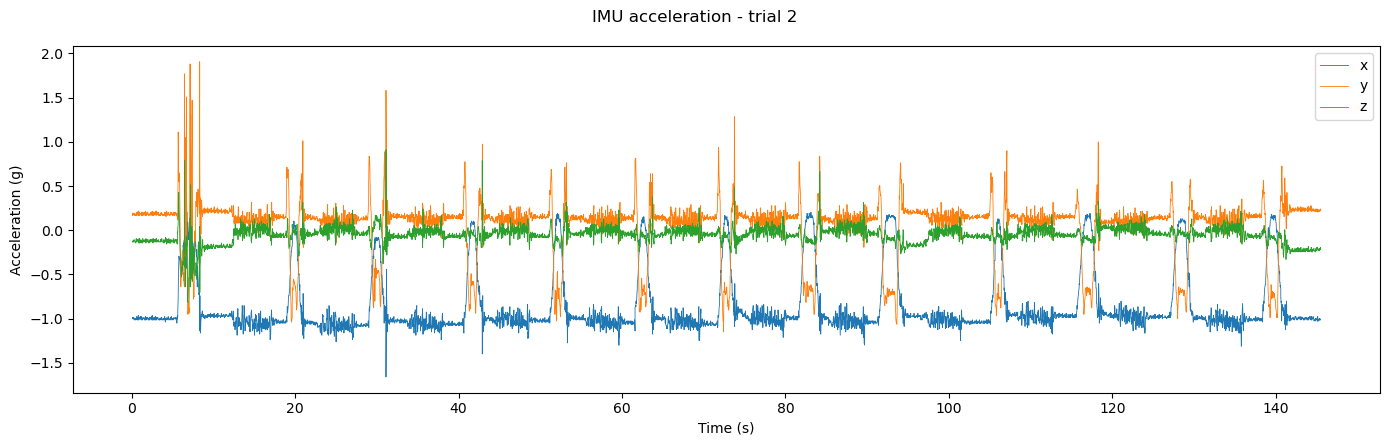

In [29]:
data = load_data('data.pkl')   # prints the shape of every entry
print('EEG trial 1 shape:', data['eeg_data1'].shape)

# Static plots for the report (raw EEG + IMU, both trials)
# Interactive version for zooming / reading cursor positions (used later for labelling):
for trial in (1, 2):
    plot_trial(data, trial,eeg_title='Raw EEG', interactive=False)


In [30]:
# plot_trial(data, 1,eeg_title='Raw EEG - Interactive', interactive=True)
# plot_trial(data, 2,eeg_title='Raw EEG - Interactive', interactive=True)

## 5. Filter and plot the EEG data with a bandpass

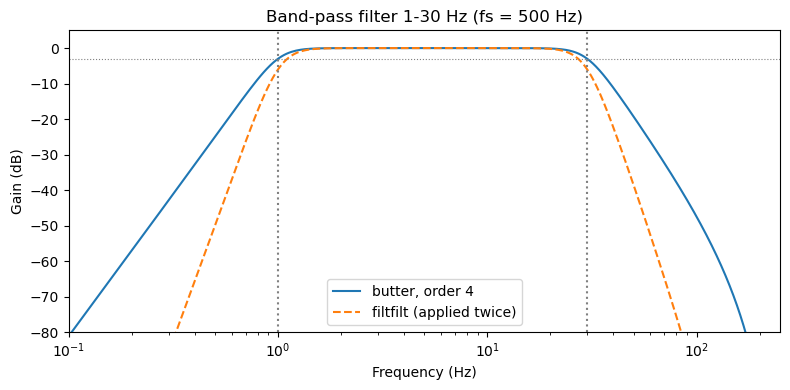

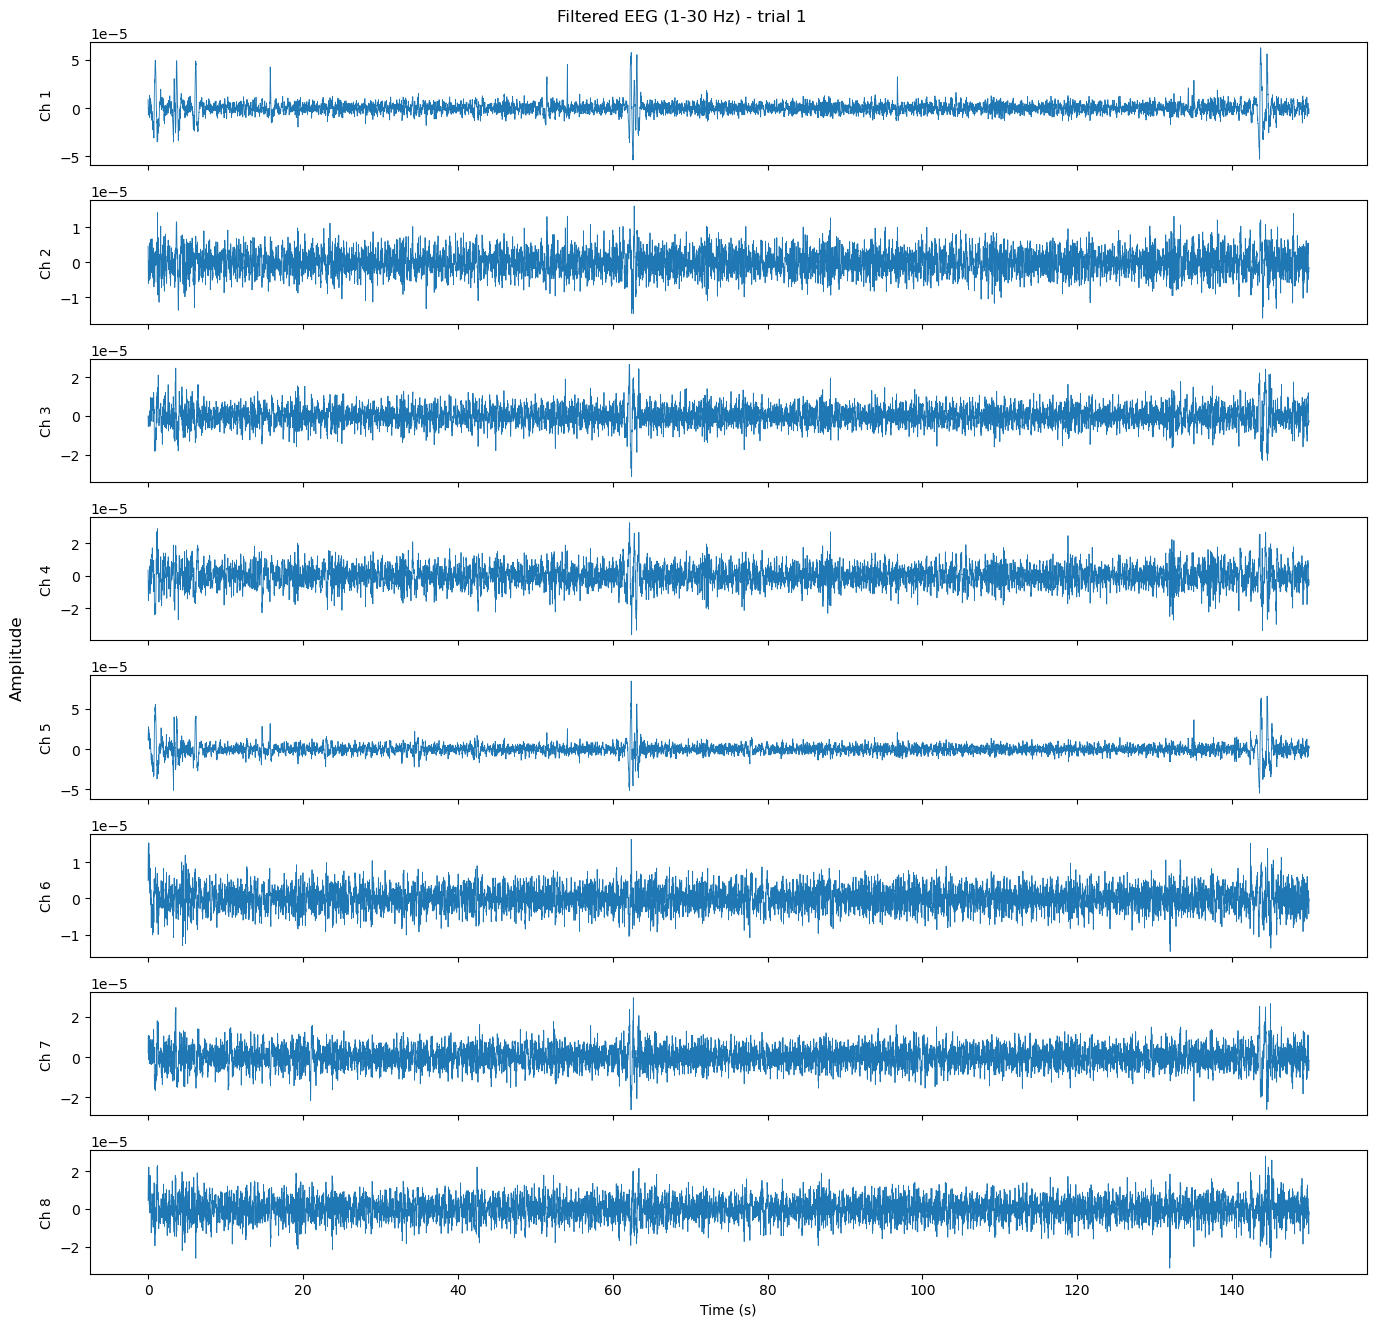

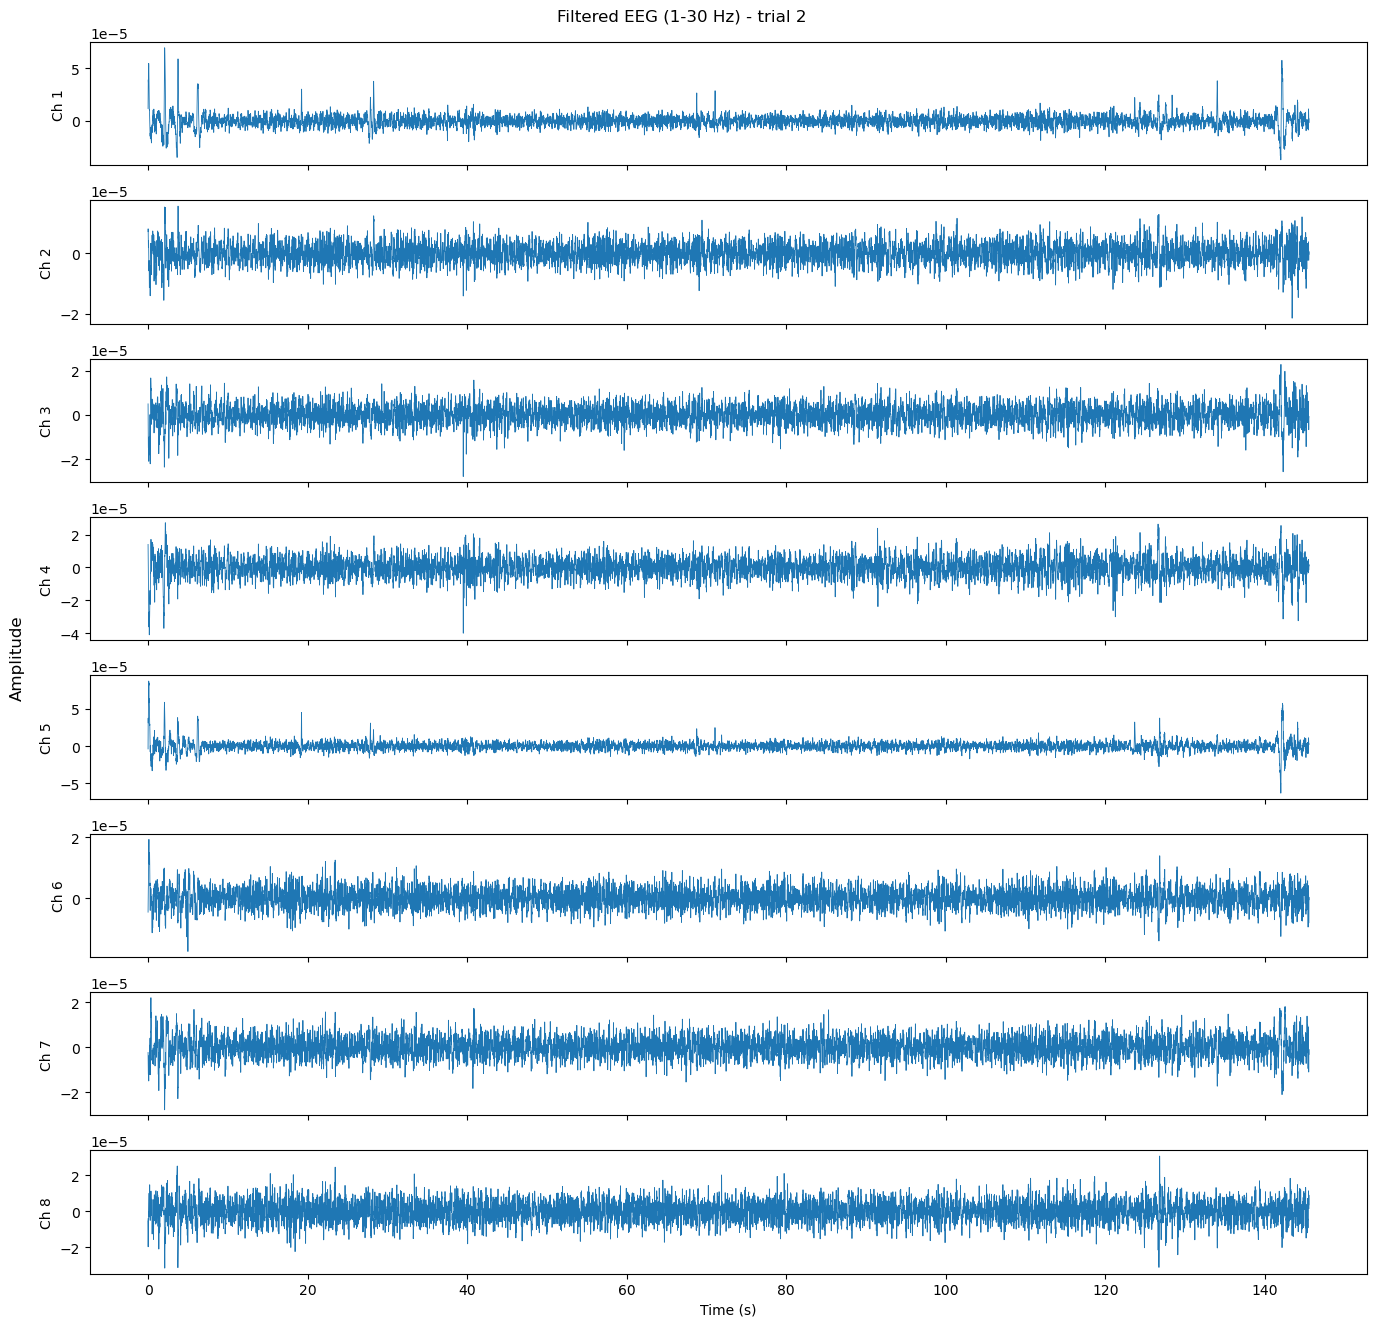

In [31]:
FS_EEG = 500                    # EEG sampling frequency (Hz)
LOW, HIGH, ORDER = 1, 30, 4     # pass band 1-30 Hz, 4th-order Butterworth

# Filter design (parameters / response for the report)
plot_filter_response(FS_EEG, LOW, HIGH, ORDER)

# Zero-phase filtering of every channel, both trials
eeg_filtered = {trial: bandpass_filter(data[f'eeg_data{trial}'], FS_EEG, LOW, HIGH, ORDER)
                for trial in (1, 2)}

# Plot the filtered EEG (same layout as the raw EEG in section 4)
for trial in (1, 2):
    d = get_trial(data, trial)
    plot_signals(d['eeg_time'], eeg_filtered[trial],
                 title=f'Filtered EEG ({LOW}-{HIGH} Hz) - trial {trial}',
                 ylabel='Amplitude', separate=True)

# Interactive version:
# plot_signals(data['eeg_timestamps1'], eeg_filtered[1], separate=True, interactive=True);

## 6 IMU based labeling

Trial 1: 31 events, durations 1.7-8.5 s, unlabelled samples before first event: 4200


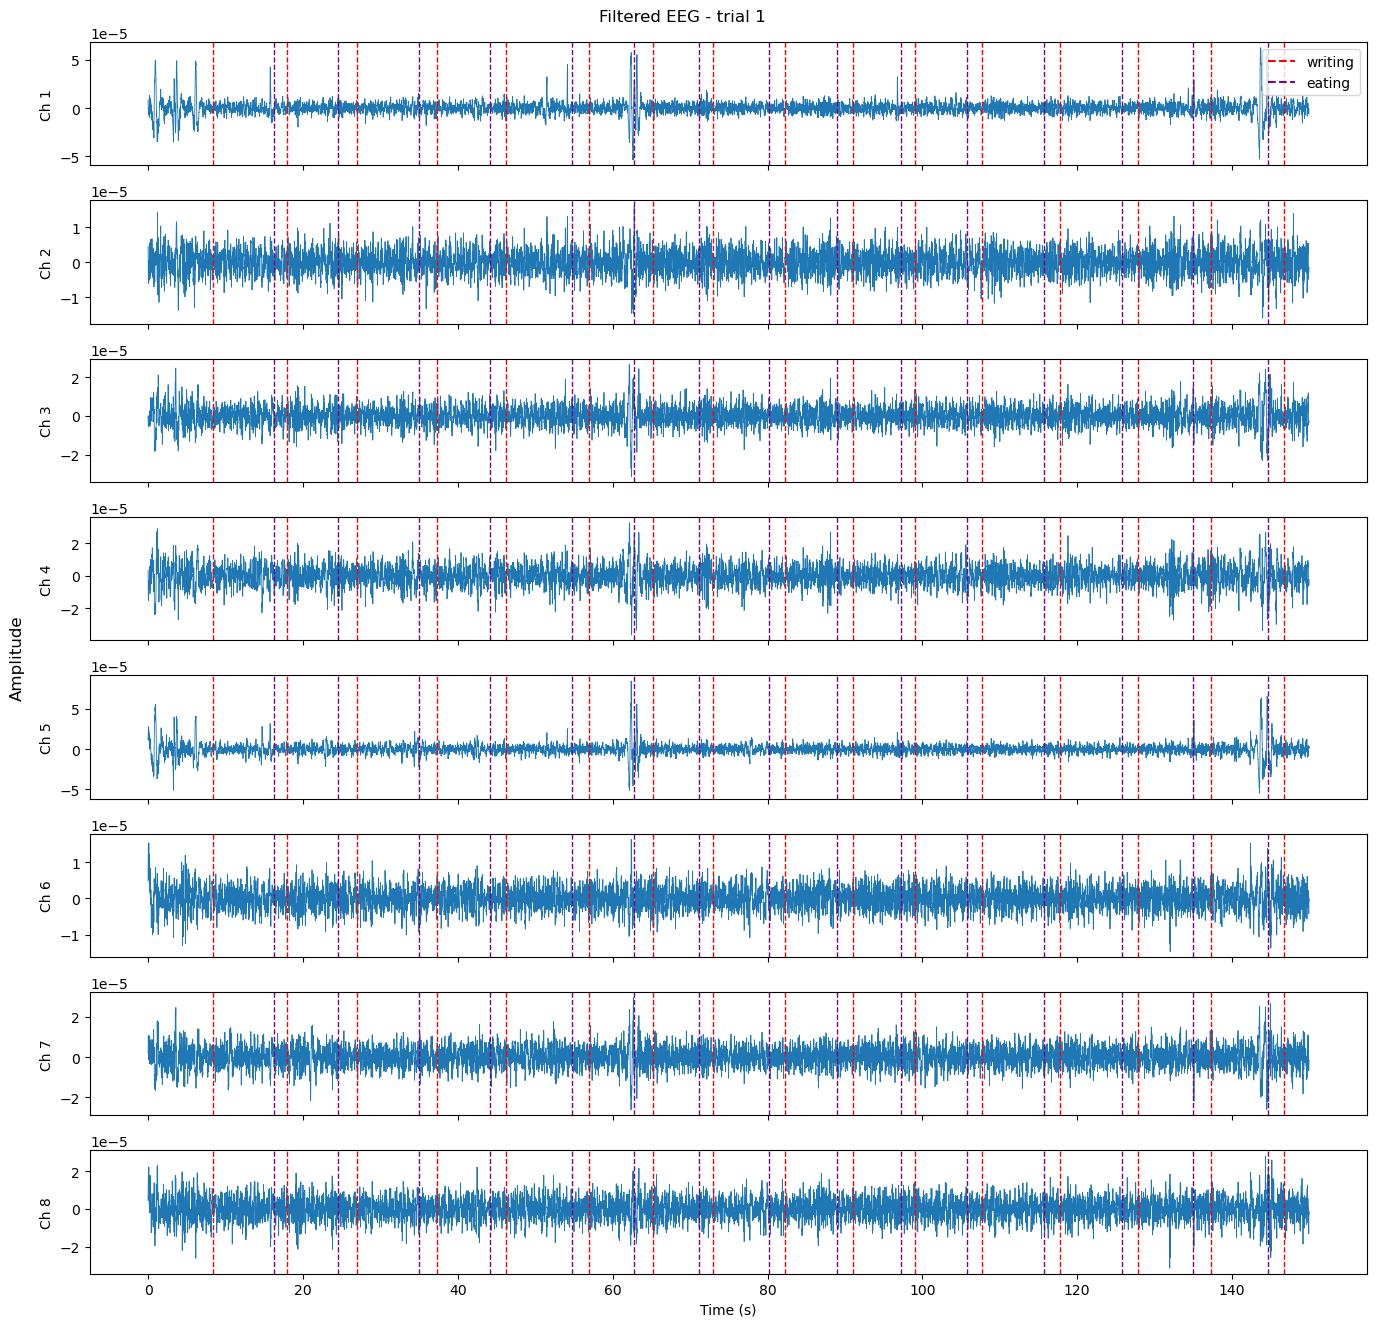

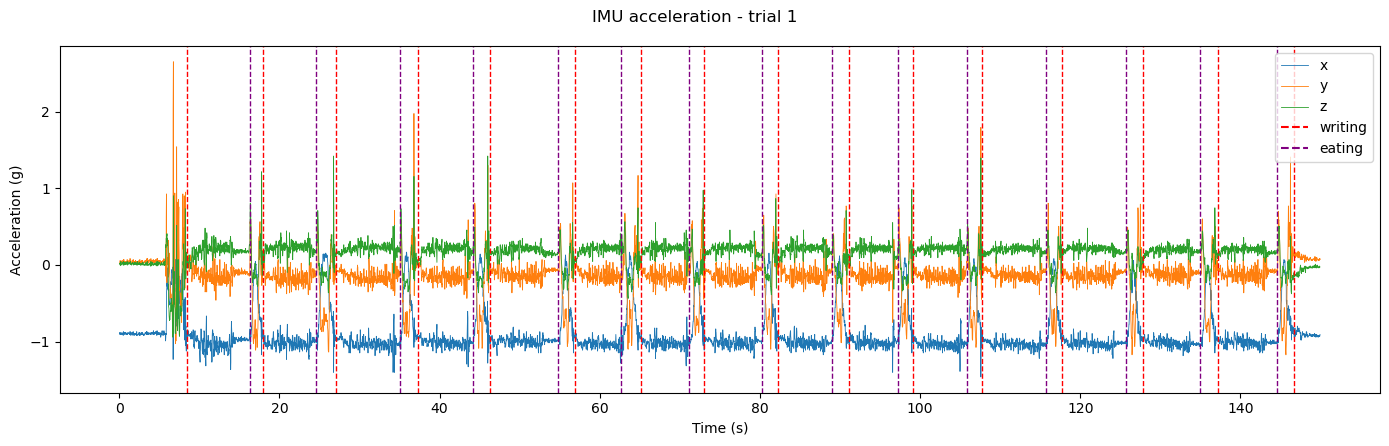

Trial 2: 25 events, durations 2.4-10.3 s, unlabelled samples before first event: 4350


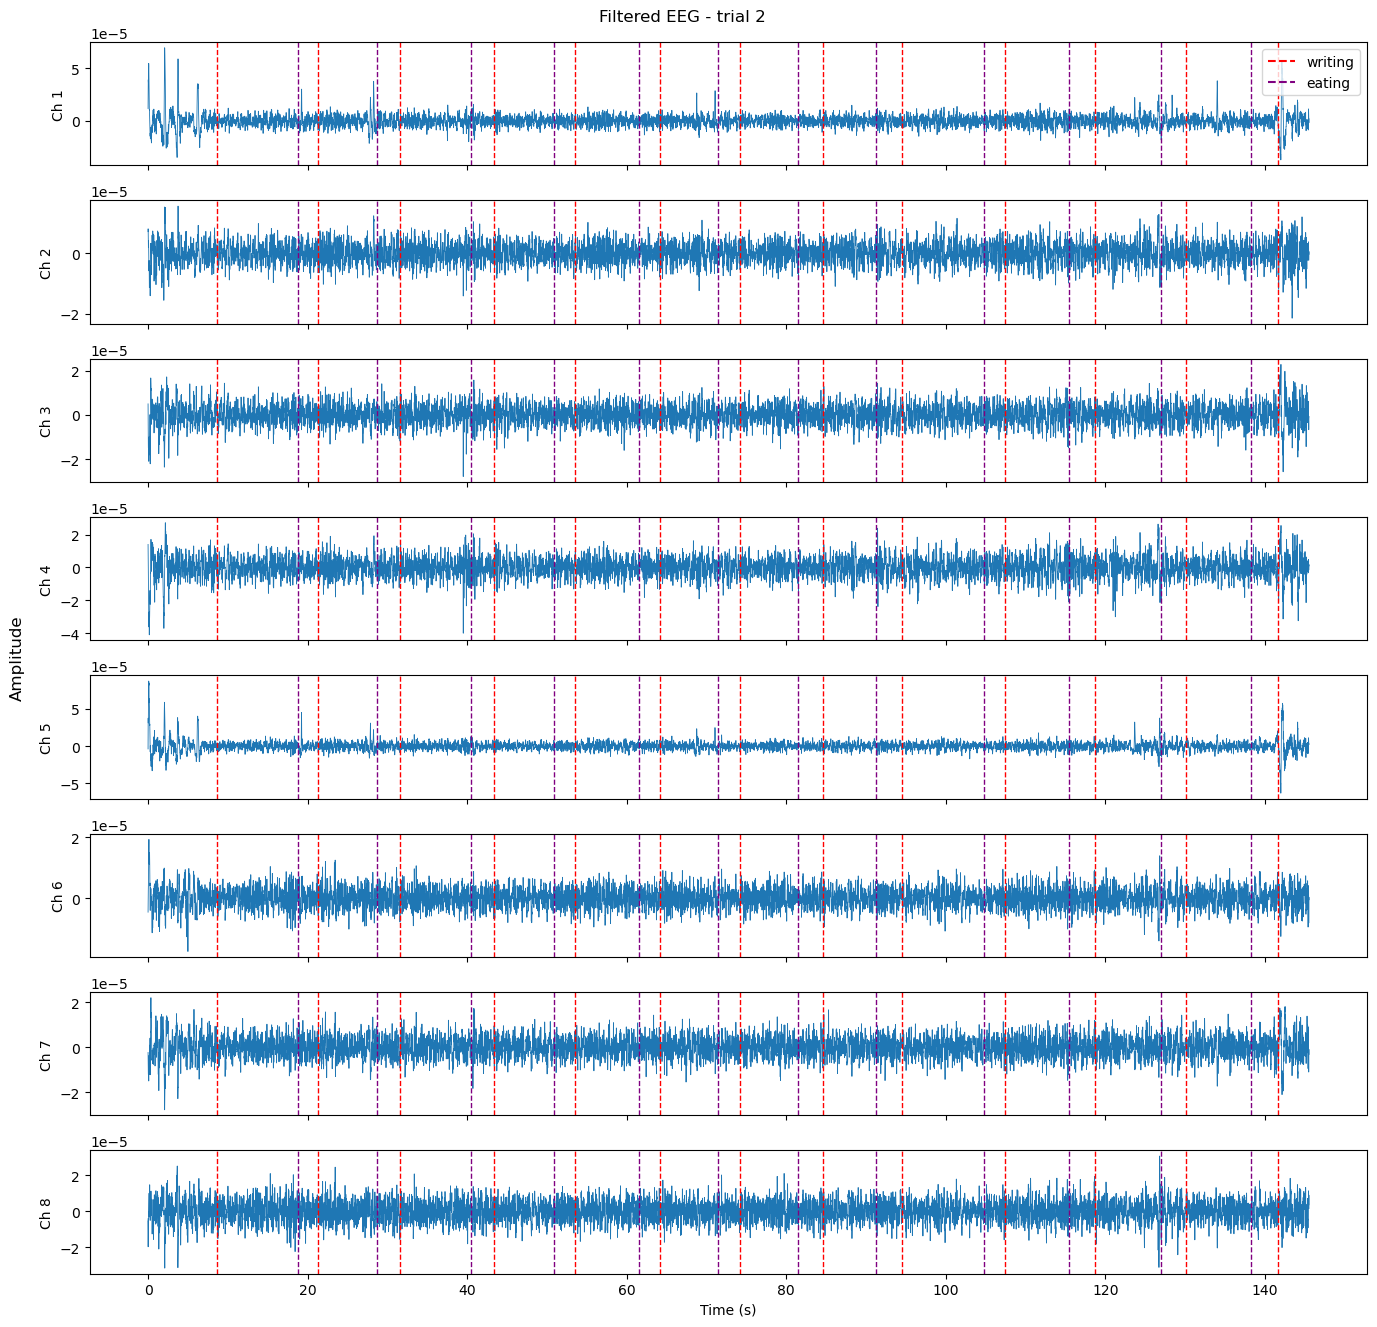

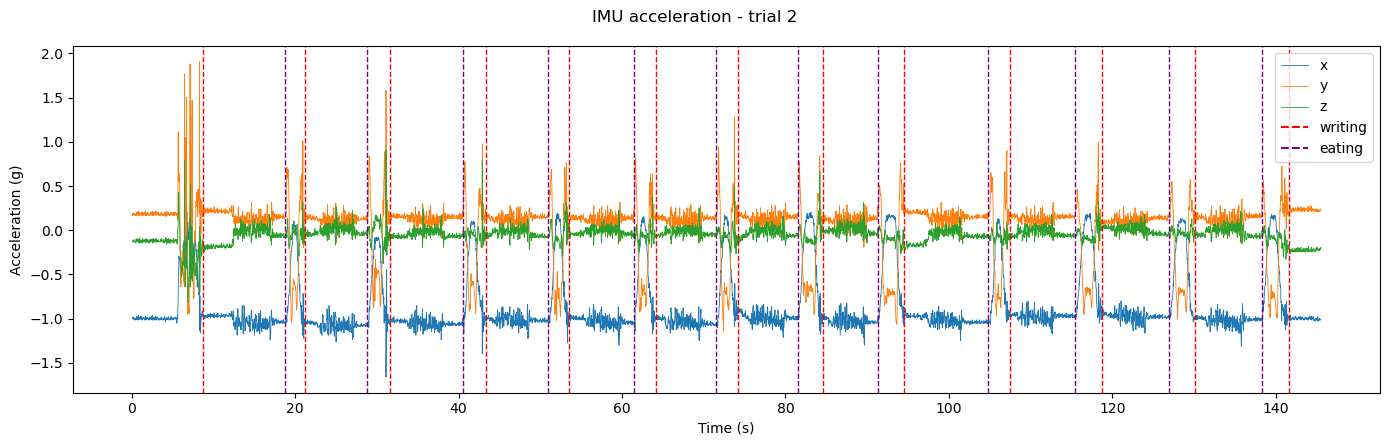

In [32]:
USE_PROVIDED_LABELS = False   # True -> use the labels stored in data.pkl instead (Q3b)
# Labels read manually from the interactive plots (cursor read-out):
early_eat_onset_starts = {
    1: np.array([8.4, 14.3, 18, 23.9, 27, 34.2, 37.25, 43.1, 46.25, 53.25, 56.9, 62.45, 65.2, 70.5, 73, 79.2, 82.25, 88, 91.1, 96.5, 99.1, 104.7, 107.75, 114.75, 117.75, 124.5, 127.8, 133.5, 137.25, 143, 146.7]),   # trial 1
    2: np.array([8.7, 17.55, 21.25, 27.65, 31.63, 38.53, 43.4, 48.75, 53.5, 59.75, 64.13, 69.85, 74.17, 80, 84.57, 90.02, 94.5, 102, 107.43, 112.75, 118.7, 124.4, 130.1, 136.2, 141.66]),        # trial 2
}
normal_eat_onset_starts = {
    1: np.array([8.4, 16.3, 18, 24.5, 27, 35, 37.25, 44.2, 46.25, 54.75, 56.9, 62.7, 65.2, 71.1, 73, 80.2, 82.25, 89, 91.1, 97.2, 99.1, 105.8, 107.75, 115.75, 117.75, 125.75, 127.8, 135, 137.25, 144.6, 146.7]),   # trial 1
    2: np.array([8.7, 18.8, 21.25, 28.75, 31.63, 40.5, 43.4, 50.9, 53.5, 61.5, 64.13, 71.5, 74.17, 81.5, 84.57, 91.27, 94.5, 104.8, 107.43, 115.43, 118.7, 126.95, 130.1, 138.27, 141.66]),        # trial 2
}

# ---- Select which labels to use ----
if USE_PROVIDED_LABELS:
    event_starts = {t: data[f'trial{t}_event_times'] for t in (1, 2)}
else:
    event_starts = normal_eat_onset_starts

for t in (1, 2):
    assert len(event_starts[t]) > 0, f'Enter the event start times for trial {t} first'
    assert np.all(np.diff(event_starts[t]) > 0), f'Trial {t}: start times must be increasing'

event_classes = {t: alternate_labels(len(event_starts[t]), ('writing', 'eating')) for t in (1, 2)}
# If your events don't alternate, write the list out instead, e.g.
# event_classes[1] = ['writing', 'eating', 'eating', ...]
# Label every EEG sample and check the labels visually on the IMU + filtered EEG
eeg_labels = {}
for t in (1, 2):
    eeg_time = data[f'eeg_timestamps{t}']
    eeg_labels[t] = label_eeg(eeg_time, event_starts[t], event_classes[t])
    durs = event_durations(event_starts[t], eeg_time[-1])
    print(f'Trial {t}: {len(event_starts[t])} events, '
          f'durations {durs.min():.1f}-{durs.max():.1f} s, '
          f'unlabelled samples before first event: {np.sum(eeg_labels[t] == -1)}')

    plot_trial(data, t, eeg=eeg_filtered[t], eeg_title='Filtered EEG',
               events=event_starts[t], event_labels=event_classes[t])



## 7 & 8. Discard the initial part and keep the first 2 s of every event
`extract_epochs` drops everything before the first event (step 7) and keeps the first `EPOCH_DURATION` seconds after each event start (step 8). For Q3, re-run from here with `EPOCH_DURATION = 1` or `4`.


In [33]:
EPOCH_DURATION = 2   # seconds kept per event (Q3: 1, 2, 4)

X_trial, y_trial = {}, {}
for t in (1, 2):
    print(f'Trial {t}:')
    X_trial[t], y_trial[t] = extract_epochs(eeg_filtered[t], data[f'eeg_timestamps{t}'],
                                            event_starts[t], event_classes[t],
                                            duration=EPOCH_DURATION, fs=FS_EEG)
    print('  X shape (events, n_channels, truncated_time):', X_trial[t].shape)


Trial 1:
  31 events x 8 channels x 1000 samples (2 s), per class: {'writing': 16, 'eating': 15}
  note: 4 events are shorter than 2 s, so their window runs into the next event
  X shape (events, n_channels, truncated_time): (31, 8, 1000)
Trial 2:
  25 events x 8 channels x 1000 samples (2 s), per class: {'writing': 13, 'eating': 12}
  X shape (events, n_channels, truncated_time): (25, 8, 1000)


## 9. Combine both trials and split into training (75%) and testing (25%) data
The split is stratified, so both classes keep the same proportion in the training and testing sets. `random_state` is fixed, so the split is the same every time you re-run.

In [34]:
TEST_SIZE = 0.25
RANDOM_STATE = 0 #seed to ensure reproducibility of the random train/test split

# Concatenate the two trials along the event axis
X_all = np.concatenate([X_trial[1], X_trial[2]], axis=0)   # (n_events, n_channels, n_samples)
y_all = np.concatenate([y_trial[1], y_trial[2]], axis=0)   # (n_events,)

train_data, test_data, train_labels, test_labels = train_test_split(
    X_all, y_all, test_size=TEST_SIZE, stratify=y_all, random_state=RANDOM_STATE)

print('All   :', X_all.shape, '| per class:', np.bincount(y_all))
print('Train :', train_data.shape, '| per class:', np.bincount(train_labels))
print('Test  :', test_data.shape, '| per class:', np.bincount(test_labels))

All   : (56, 8, 1000) | per class: [29 27]
Train : (42, 8, 1000) | per class: [22 20]
Test  : (14, 8, 1000) | per class: [7 7]


## 10 Self-implemented CSP

In [35]:
def manual_csp(train_data, train_labels):

    # Calculate mean covariance matrix for each class
    covs = []
    for label in np.unique(train_labels):
        events = train_data[train_labels == label]
        covs.append(np.mean([np.cov(event) for event in events], axis=0))

    C1, C2 = covs

    # Compute CSP eigenvalues and eigenvectors
    eigvals, eigvecs = np.linalg.eig(np.linalg.inv(C1 + C2) @ C1)

    # Sort eigenvalues from largest to smallest
    idx = np.argsort(eigvals)[::-1]

    w = np.real(eigvecs[:, idx])
    eigvals = np.real(eigvals[idx])

    return w, eigvals

w, eigvals = manual_csp(train_data, train_labels)

print("CSP weights:", w.shape)
print("Eigenvalues:", eigvals)

CSP weights: (8, 8)
Eigenvalues: [0.73484229 0.56889162 0.55663472 0.53421431 0.51822026 0.49926479
 0.46584164 0.4422399 ]


## 11 Normalization and Standardization


In [36]:
import numpy as np

for i in range(w.shape[1]):
    w[:, i] /= np.linalg.norm(w[:, i])
    w[:, i]*= np.sign(w[0, i])

print("Normalized CSP weights shape:", w.shape)
print("Column norms:", np.linalg.norm(w, axis=0))
print("Normalized CSP weights:\n", w)

Normalized CSP weights shape: (8, 8)
Column norms: [1. 1. 1. 1. 1. 1. 1. 1.]
Normalized CSP weights:
 [[ 0.67924294  0.33686054  0.07211565  0.1427383   0.20864402  0.24030937
   0.43856929  0.28443495]
 [-0.51522016 -0.89165242 -0.08073711  0.48352549  0.53216235 -0.17844399
  -0.21722296 -0.05497345]
 [ 0.24826147  0.15802428  0.05502143 -0.00303277 -0.55861649  0.32292535
   0.39588865 -0.5096041 ]
 [-0.26668535  0.16532263 -0.12178017 -0.10796819 -0.29338112 -0.09999542
  -0.35909472  0.40832003]
 [ 0.26822686 -0.14710883  0.06177774  0.02153422 -0.35701793 -0.34032652
  -0.42660802 -0.40168831]
 [-0.12813336 -0.04945285 -0.93514133 -0.72864994  0.1275298   0.55835729
   0.5252608   0.4855047 ]
 [ 0.0909247   0.03171815 -0.00434141  0.35384368  0.17324785 -0.56582905
  -0.04492859  0.03733246]
 [-0.20926364  0.11868051  0.30347725  0.27850088  0.31844241  0.21995854
  -0.12199359 -0.3019786 ]]


## 12 Plot Topography

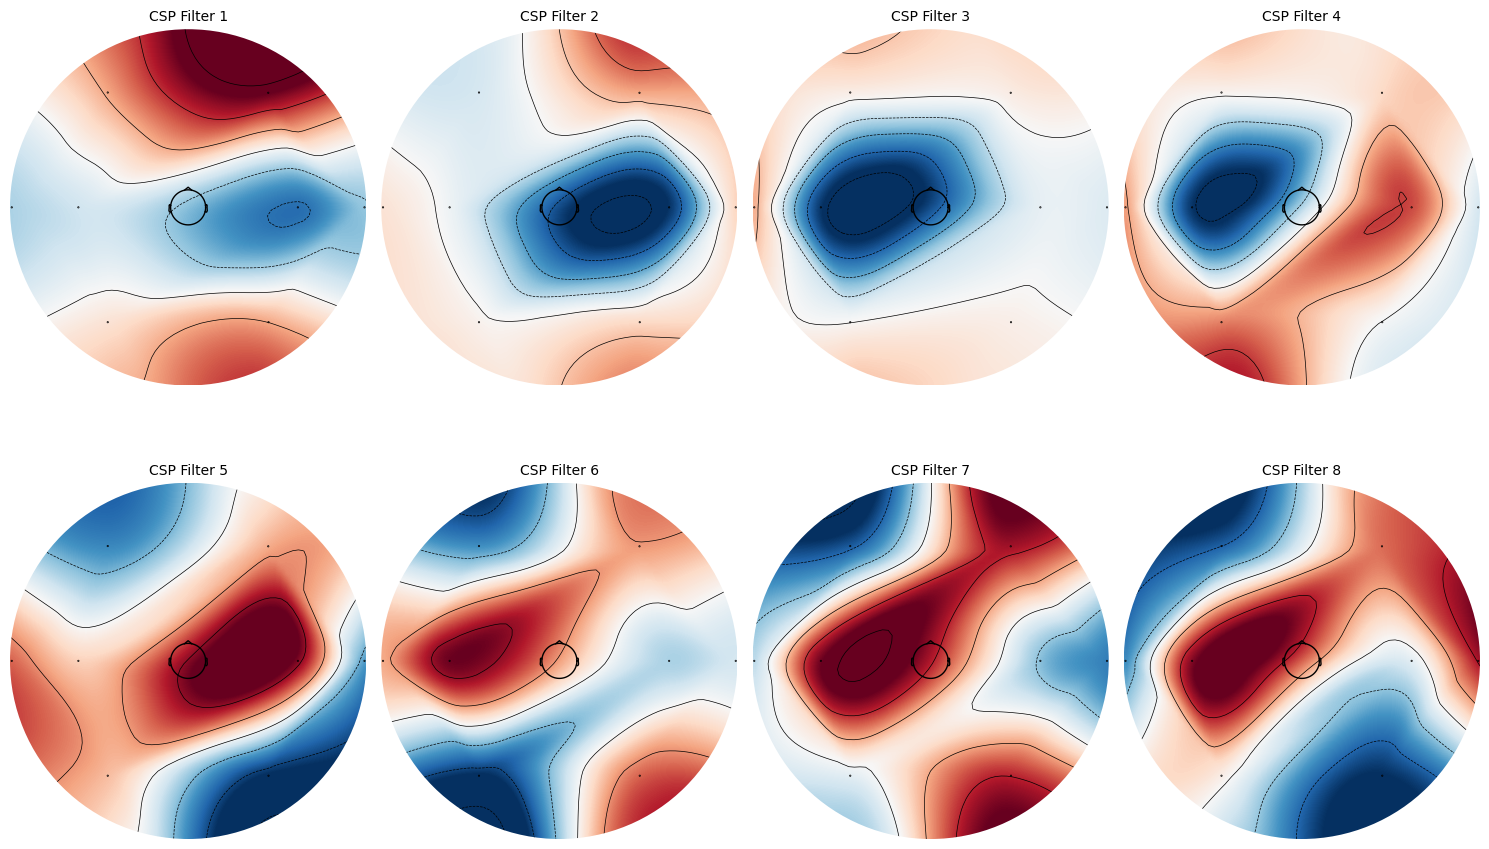

In [37]:
from mne.viz import plot_topomap

chans = data['chans']
# Plot topomap
fig, axes = plt.subplots(2, 4, figsize=(15, 10))
for i in range(w.shape[1]):
    ax = axes[i // 4, i % 4]
    plot_topomap(w[:, i], chans, axes=ax, show=False)
    ax.set_title(f'CSP Filter {i+1}', fontsize=10)
plt.tight_layout()
plt.show()

## 13 Comparison of manual CSP and MNE CSP

Computing rank from data with rank=None
    Using tolerance 3.2e-06 (2.2e-16 eps * 8 dim * 1.8e+09  max singular value)
    Estimated rank (data): 8
    data: rank 8 computed from 8 data channels with 0 projectors
Reducing data rank from 8 -> 8
Estimating class=0 covariance using EMPIRICAL
Done.
Estimating class=1 covariance using EMPIRICAL
Done.
Manual CSP weights:
 [[ 0.679  0.337  0.072  0.143  0.209  0.24   0.439  0.284]
 [-0.515 -0.892 -0.081  0.484  0.532 -0.178 -0.217 -0.055]
 [ 0.248  0.158  0.055 -0.003 -0.559  0.323  0.396 -0.51 ]
 [-0.267  0.165 -0.122 -0.108 -0.293 -0.1   -0.359  0.408]
 [ 0.268 -0.147  0.062  0.022 -0.357 -0.34  -0.427 -0.402]
 [-0.128 -0.049 -0.935 -0.729  0.128  0.558  0.525  0.486]
 [ 0.091  0.032 -0.004  0.354  0.173 -0.566 -0.045  0.037]
 [-0.209  0.119  0.303  0.279  0.318  0.22  -0.122 -0.302]]

MNE CSP weights:
 [[ 0.681  0.28   0.438  0.239  0.21   0.141  0.338  0.074]
 [-0.51  -0.054 -0.219 -0.177  0.534  0.477 -0.891 -0.08 ]
 [ 0.249 -0.517  0.3

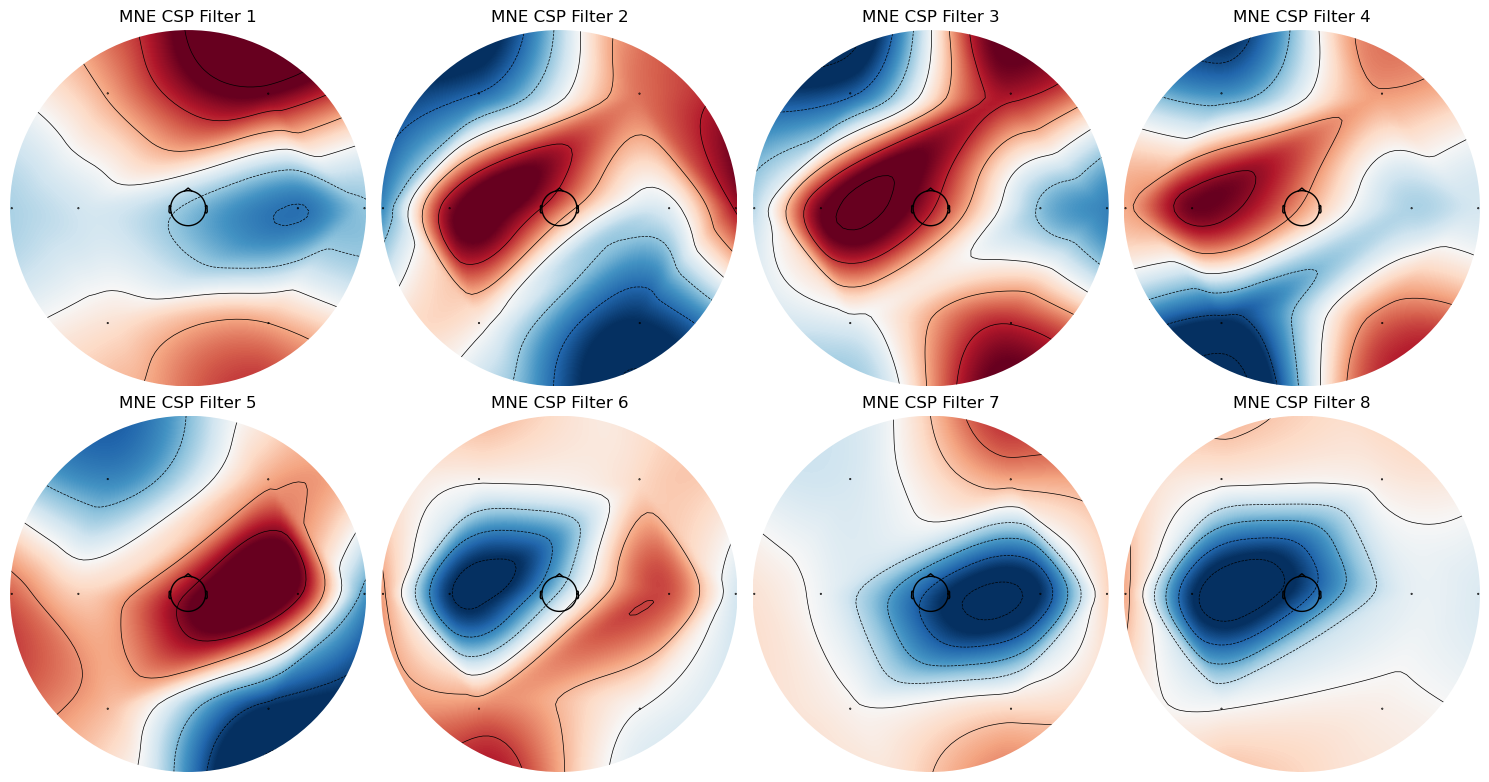

In [38]:

import numpy as np
import matplotlib.pyplot as plt
import mne.decoding
from mne.viz import plot_topomap

# check the shape of train_data and transpose if necessary
X = np.asarray(train_data)
if X.shape[1] != 8:
    X = X.transpose(0, 2, 1)

# MNE CSP 
csp = mne.decoding.CSP(n_components=8, reg=None, log=None, norm_trace=True)
csp.fit(train_data, train_labels)

w_mne = csp.filters_.T.copy()
for i in range(w_mne.shape[1]):
    w_mne[:, i] /= np.linalg.norm(w_mne[:, i])
    if w_mne[0, i] != 0:
        w_mne[:, i] *= np.sign(w_mne[0, i])

# print weights
print("Manual CSP weights:\n", np.round(w, 3))
print("\nMNE CSP weights:\n", np.round(w_mne, 3))

# Plot the 8 MNE topographies
fig, axes = plt.subplots(2, 4, figsize=(15, 8))
for i in range(8):
    ax = axes[i // 4, i % 4]
    plot_topomap(w_mne[:, i], data['chans'], axes=ax, show=False)
    ax.set_title(f"MNE CSP Filter {i+1}")

plt.tight_layout()
plt.show()


## 14 Selection of the 6 CSP filters

In [39]:
w_selected = np.hstack((w[:, :3], w[:, -3:]))

print("Selected CSP weights shape:", w_selected.shape)
print("Selected eigenvalues:", np.concatenate((eigvals[:3], eigvals[-3:])))
print("Selected CSP weights:\n", w_selected)

Selected CSP weights shape: (8, 6)
Selected eigenvalues: [0.73484229 0.56889162 0.55663472 0.49926479 0.46584164 0.4422399 ]
Selected CSP weights:
 [[ 0.67924294  0.33686054  0.07211565  0.24030937  0.43856929  0.28443495]
 [-0.51522016 -0.89165242 -0.08073711 -0.17844399 -0.21722296 -0.05497345]
 [ 0.24826147  0.15802428  0.05502143  0.32292535  0.39588865 -0.5096041 ]
 [-0.26668535  0.16532263 -0.12178017 -0.09999542 -0.35909472  0.40832003]
 [ 0.26822686 -0.14710883  0.06177774 -0.34032652 -0.42660802 -0.40168831]
 [-0.12813336 -0.04945285 -0.93514133  0.55835729  0.5252608   0.4855047 ]
 [ 0.0909247   0.03171815 -0.00434141 -0.56582905 -0.04492859  0.03733246]
 [-0.20926364  0.11868051  0.30347725  0.21995854 -0.12199359 -0.3019786 ]]


## 15 Feature extraction using CSP variances

In [40]:
def extract_csp_features(eeg_data, w_selected):
    features = []

    for event in eeg_data:
        # Project EEG data onto the 6 CSP filters
        projected = w_selected.T @ event

        # Calculate variance of each projected channel
        variances = np.diag(np.cov(projected))

        features.append(variances)

    return np.array(features)


# Extract features for training and testing
train_features = extract_csp_features(train_data, w_selected)
test_features = extract_csp_features(test_data, w_selected)

print("Training features shape:", train_features.shape)
print("Testing features shape:", test_features.shape)
print("First event features:", train_features[0])

Training features shape: (42, 6)
Testing features shape: (14, 6)
First event features: [3.46436110e-12 1.46092890e-12 3.14302974e-12 1.36635710e-12
 1.96241983e-12 3.18799562e-12]


## 16 Self-implemented LDA

In [41]:
def LDA(x_train, y_train):

    # Separate the two classes
    classes = np.unique(y_train)

    X1 = x_train[y_train == classes[0]]
    X2 = x_train[y_train == classes[1]]

    # Compute class means
    mu1 = np.mean(X1, axis=0)
    mu2 = np.mean(X2, axis=0)

    # Within-class scatter matrix
    S_W = ((X1 - mu1).T @ (X1 - mu1)
         + (X2 - mu2).T @ (X2 - mu2))

    # Between-class scatter matrix
    mean_diff = mu1 - mu2
    S_B = np.outer(mean_diff, mean_diff)

    # Eigenvalue decomposition
    eigenvalues, eigenvectors = np.linalg.eig(
        np.linalg.pinv(S_W) @ S_B
    )

    # Sort eigenvalues in descending order
    idx = np.argsort(eigenvalues.real)[::-1]

    # Select the most discriminative eigenvector
    w_lda = eigenvectors[:, idx[0]].real

    # Normalize the LDA weights
    w_lda /= np.linalg.norm(w_lda)

    return w_lda

# 17

In [42]:
w_lda = LDA(train_features, train_labels)

print("LDA weights:", w_lda)
print("Shape:", w_lda.shape)

# Project training and testing features
train_proj = train_features @ w_lda
test_proj = test_features @ w_lda

classes = np.unique(train_labels)

# Compute projected class means
m1 = np.mean(train_proj[train_labels == classes[0]])
m2 = np.mean(train_proj[train_labels == classes[1]])

# Classification threshold
threshold = (m1 + m2) / 2

# Determine class ordering
low, high = classes if m1 < m2 else classes[::-1]

# Classification
prediction_train = np.where(train_proj < threshold, low, high)
prediction_test = np.where(test_proj < threshold, low, high)

# Compute accuracy
accuracy_train = np.mean(prediction_train == train_labels)
accuracy_test = np.mean(prediction_test == test_labels)

print(f"Training accuracy: {accuracy_train:.2%}")
print(f"Testing accuracy: {accuracy_test:.2%}")

LDA weights: [ 0.00839254 -0.63973311 -0.73174226 -0.1807829   0.11334388  0.09846362]
Shape: (6,)
Training accuracy: 85.71%
Testing accuracy: 64.29%


# 18

In [43]:
# Initialize and train the LDA classifier
model = LinearDiscriminantAnalysis()
model.fit(train_features, train_labels)

# Predict training and testing labels
prediction_train_sklearn = model.predict(train_features)
prediction_test_sklearn = model.predict(test_features)

# Compute accuracy
accuracy_train_sklearn = np.mean(prediction_train_sklearn == train_labels)
accuracy_test_sklearn = np.mean(prediction_test_sklearn == test_labels)

# Compare both implementations
print("Manual LDA:")
print(f"Training accuracy: {accuracy_train:.2%}")
print(f"Testing accuracy: {accuracy_test:.2%}")

print("\nScikit-learn LDA:")
print(f"Training accuracy: {accuracy_train_sklearn:.2%}")
print(f"Testing accuracy: {accuracy_test_sklearn:.2%}")

Manual LDA:
Training accuracy: 85.71%
Testing accuracy: 64.29%

Scikit-learn LDA:
Training accuracy: 85.71%
Testing accuracy: 57.14%


# 19

In [44]:
# Standardize the features
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(train_features)
x_test_scaled = scaler.transform(test_features)

# SVM with polynomial kernel of degree 2
SVM2 = SVC(kernel='poly', degree=2, random_state=0)
SVM2.fit(x_train_scaled, train_labels)

svm2_prediction_train = SVM2.predict(x_train_scaled)
svm2_prediction_test = SVM2.predict(x_test_scaled)

accuracy_train_svm2 = np.mean(svm2_prediction_train == train_labels)
accuracy_test_svm2 = np.mean(svm2_prediction_test == test_labels)

# SVM with polynomial kernel of degree 6
SVM6 = SVC(kernel='poly', degree=6, random_state=0)
SVM6.fit(x_train_scaled, train_labels)

svm6_prediction_train = SVM6.predict(x_train_scaled)
svm6_prediction_test = SVM6.predict(x_test_scaled)

accuracy_train_svm6 = np.mean(svm6_prediction_train == train_labels)
accuracy_test_svm6 = np.mean(svm6_prediction_test == test_labels)

# Display results
print("SVM degree 2:")
print(f"Training accuracy: {accuracy_train_svm2:.2%}")
print(f"Testing accuracy: {accuracy_test_svm2:.2%}")

print("\nSVM degree 6:")
print(f"Training accuracy: {accuracy_train_svm6:.2%}")
print(f"Testing accuracy: {accuracy_test_svm6:.2%}")


results = pd.DataFrame({
    "Classifier": ["Manual LDA", "Sklearn LDA", "SVM degree 2", "SVM degree 6"],
    "Training accuracy (%)": [
        accuracy_train * 100,
        accuracy_train_sklearn * 100,
        accuracy_train_svm2 * 100,
        accuracy_train_svm6 * 100
    ],
    "Testing accuracy (%)": [
        accuracy_test * 100,
        accuracy_test_sklearn * 100,
        accuracy_test_svm2 * 100,
        accuracy_test_svm6 * 100
    ]
})

display(results.round(2))

SVM degree 2:
Training accuracy: 54.76%
Testing accuracy: 50.00%

SVM degree 6:
Training accuracy: 54.76%
Testing accuracy: 57.14%


,Classifier,Training accuracy (%),Testing accuracy (%)
0,Manual LDA,85.71,64.29
1,Sklearn LDA,85.71,57.14
2,SVM degree 2,54.76,50.00
3,SVM degree 6,54.76,57.14
